In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
!pip install ucimlrepo

In [4]:
from ucimlrepo import fetch_ucirepo

student_performance = fetch_ucirepo(id=320)

X = student_performance.data.features
y = student_performance.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")

print(df.head().to_string(index=False))

Dataset loaded successfully!
school sex  age address famsize Pstatus  Medu  Fedu    Mjob     Fjob reason guardian  traveltime  studytime  failures schoolsup famsup paid activities nursery higher internet romantic  famrel  freetime  goout  Dalc  Walc  health  absences  G1  G2  G3
    GP   F   18       U     GT3       A     4     4 at_home  teacher course   mother           2          2         0       yes     no   no         no     yes    yes       no       no       4         3      4     1     1       3         4   0  11  11
    GP   F   17       U     GT3       T     1     1 at_home    other course   father           1          2         0        no    yes   no         no      no    yes      yes       no       5         3      3     1     1       3         2   9  11  11
    GP   F   15       U     LE3       T     1     1 at_home    other  other   mother           1          2         0       yes     no   no         no     yes    yes      yes       no       4         3      2     2    

In [5]:
print("First five records:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

print("\nColumn names:")
print(df.columns.tolist())

First five records:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]

Dataset shape:
(649, 33)

Dataset information:
<class 'pandas.core.

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset cleaned successfully!")

print("Remaining records:", len(df))

Missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values:
0

Duplicate records:
0
Dataset cleaned successfully!
Remaining records: 649


In [7]:
selected_columns = [
    "age",
    "sex",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "G3"
]

print(df[selected_columns].head(10))

   age sex  studytime  failures  absences  G1  G2  G3
0   18   F          2         0         4   0  11  11
1   17   F          2         0         2   9  11  11
2   15   F          2         0         6  12  13  12
3   15   F          3         0         0  14  14  14
4   16   F          2         0         0  11  13  13
5   16   M          2         0         6  12  12  13
6   16   M          2         0         0  13  12  13
7   17   F          2         0         2  10  13  13
8   15   M          2         0         0  15  16  17
9   15   M          2         0         0  12  12  13


In [8]:
print("Student Performance Summary")

print("\nAverage First Period Grade:")
print(round(df["G1"].mean(), 2))

print("\nAverage Second Period Grade:")
print(round(df["G2"].mean(), 2))

print("\nAverage Final Grade:")
print(round(df["G3"].mean(), 2))

print("\nHighest Final Grade:")
print(df["G3"].max())

print("\nLowest Final Grade:")
print(df["G3"].min())

Student Performance Summary

Average First Period Grade:
11.4

Average Second Period Grade:
11.57

Average Final Grade:
11.91

Highest Final Grade:
19

Lowest Final Grade:
0


In [9]:
study_analysis = df.groupby("studytime")["G3"].mean()

print("Average Final Grade by Study Time:")
print(study_analysis.round(2))

Average Final Grade by Study Time:
studytime
1    10.84
2    12.09
3    13.23
4    13.06
Name: G3, dtype: float64


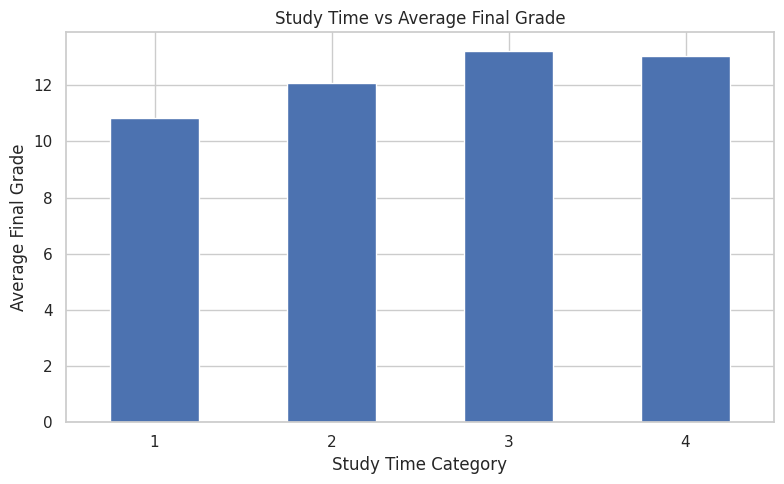

In [10]:
plt.figure(figsize=(8, 5))

study_analysis.plot(kind="bar")

plt.title("Study Time vs Average Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("Study Time Analysis.png")
plt.show()

In [11]:
failure_analysis = df.groupby("failures")["G3"].mean()

print("Average Final Grade by Past Failures:")
print(failure_analysis.round(2))

Average Final Grade by Past Failures:
failures
0    12.51
1     8.64
2     8.81
3     8.07
Name: G3, dtype: float64


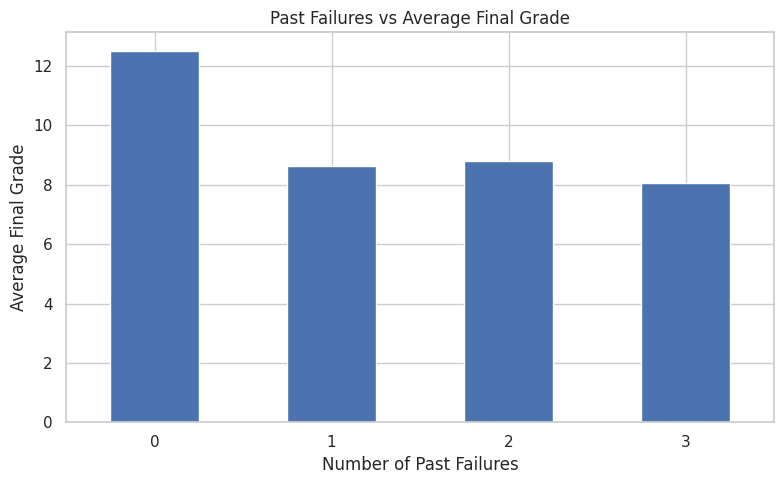

In [12]:
plt.figure(figsize=(8, 5))

failure_analysis.plot(kind="bar")

plt.title("Past Failures vs Average Final Grade")
plt.xlabel("Number of Past Failures")
plt.ylabel("Average Final Grade")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("Past Failures Analysis.png")
plt.show()

Average Grades:
G1    11.40
G2    11.57
G3    11.91
dtype: float64


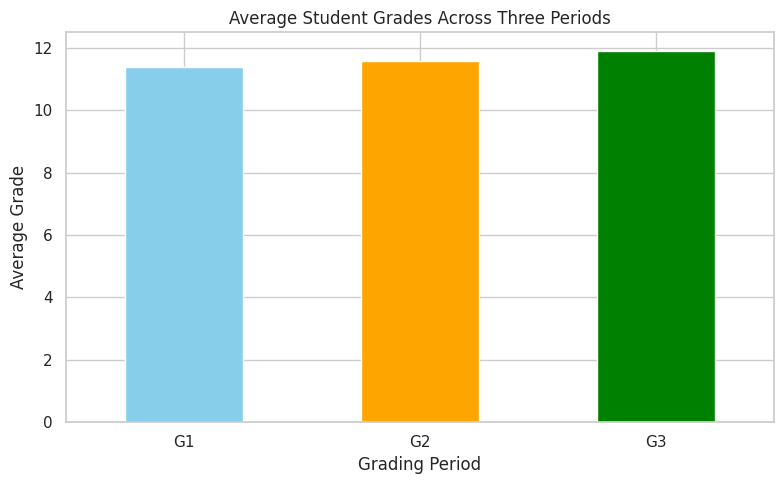

In [13]:
grade_averages = df[["G1", "G2", "G3"]].mean()

print("Average Grades:")
print(grade_averages.round(2))

plt.figure(figsize=(8, 5))

grade_averages.plot(
    kind="bar",
    color=["skyblue", "orange", "green"]
)

plt.title("Average Student Grades Across Three Periods")
plt.xlabel("Grading Period")
plt.ylabel("Average Grade")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("Grade Comparison.png")
plt.show()

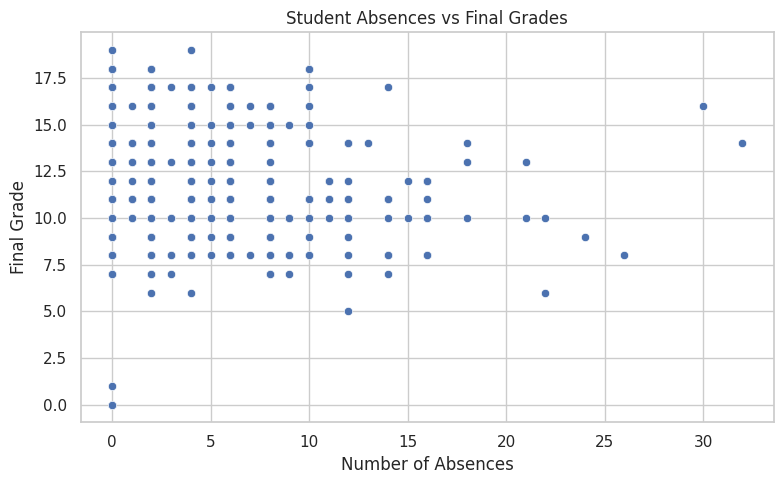

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3"
)

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.tight_layout()
plt.savefig("Absences vs Grades.png")
plt.show()

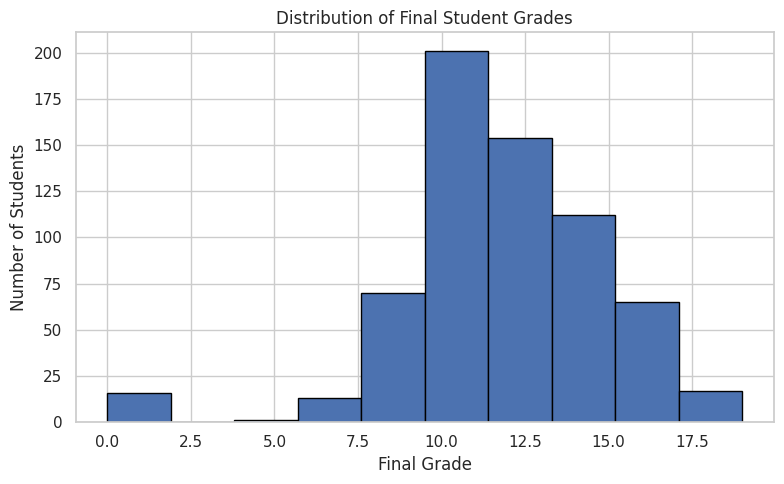

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["G3"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("Final Grade Distribution.png")
plt.show()

           studytime  failures  absences    G1    G2    G3
studytime       1.00     -0.15     -0.12  0.26  0.24  0.25
failures       -0.15      1.00      0.12 -0.38 -0.39 -0.39
absences       -0.12      0.12      1.00 -0.15 -0.12 -0.09
G1              0.26     -0.38     -0.15  1.00  0.86  0.83
G2              0.24     -0.39     -0.12  0.86  1.00  0.92
G3              0.25     -0.39     -0.09  0.83  0.92  1.00


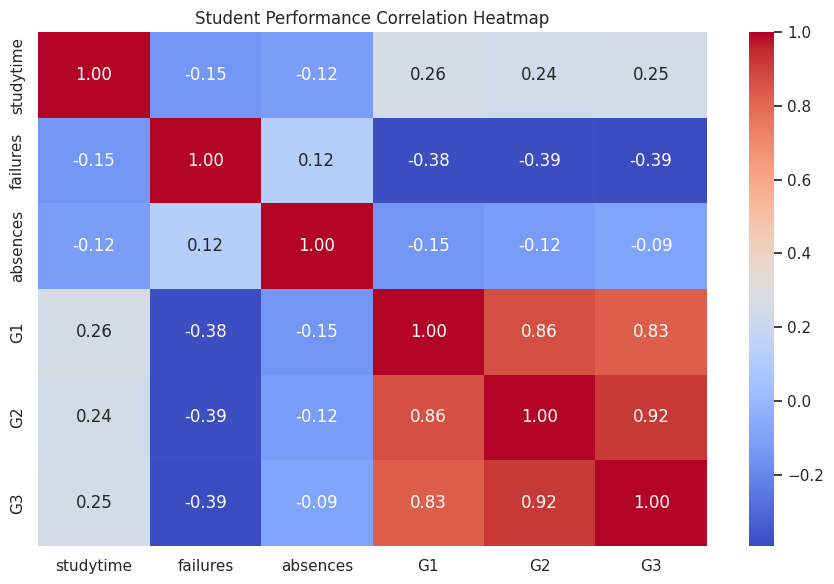

In [16]:
correlation = df[
    ["studytime", "failures", "absences", "G1", "G2", "G3"]
].corr()

print(correlation.round(2))

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Performance Correlation Heatmap")

plt.tight_layout()
plt.savefig("Correlation Heatmap.png")
plt.show()

In [17]:
print("FINAL DATA ANALYSIS FINDINGS")
print("=" * 35)

print("\nTotal Student Records:", len(df))

print("\nAverage Final Grade:")
print(round(df["G3"].mean(), 2))

print("\nHighest Final Grade:")
print(df["G3"].max())

print("\nLowest Final Grade:")
print(df["G3"].min())

print("\nAverage Grade by Study Time:")
print(df.groupby("studytime")["G3"].mean().round(2))

print("\nAverage Grade by Past Failures:")
print(df.groupby("failures")["G3"].mean().round(2))

print("\nCorrelation with Final Grade:")
print(
    df[["studytime", "failures", "absences", "G1", "G2", "G3"]]
    .corr()["G3"].round(2)
)

FINAL DATA ANALYSIS FINDINGS

Total Student Records: 649

Average Final Grade:
11.91

Highest Final Grade:
19

Lowest Final Grade:
0

Average Grade by Study Time:
studytime
1    10.84
2    12.09
3    13.23
4    13.06
Name: G3, dtype: float64

Average Grade by Past Failures:
failures
0    12.51
1     8.64
2     8.81
3     8.07
Name: G3, dtype: float64

Correlation with Final Grade:
studytime    0.25
failures    -0.39
absences    -0.09
G1           0.83
G2           0.92
G3           1.00
Name: G3, dtype: float64


In [18]:
df.to_csv("Analyzed Student Performance.csv", index=False)

print("Analyzed dataset exported successfully!")

Analyzed dataset exported successfully!
